# 🟢 1. Basics: Sequence Modeling & Simple RNN Foundations

### *Why ANNs Fail on Sequences, Unrolling Recurrence Across Time, Hidden State Transitions, and Backpropagation Through Time (BPTT)*

---

## 📌 Module Overview
1. **Why Feedforward ANNs Fail on Sequential Data**:
   - Fixed input/output vector dimensions.
   - Complete lack of temporal parameter sharing.
   - No recurrence or hidden state memory.
2. **The Recurrent Neuron & Unrolling Through Time**:
   - Input $x_t \in \mathbb{R}^d$, Hidden State $h_t \in \mathbb{R}^h$.
   - Recurrent state transition formula:
     $$h_t = 	anh(W_{hh} h_{t-1} + W_{xh} x_t + b_h)$$
   - Output prediction formula:
     $$\hat{y}_t = 	ext{Softmax}(W_{hy} h_t + b_y)$$
3. **Backpropagation Through Time (BPTT)**:
   - Calculating gradients across time unrollings:
     $$rac{\partial \mathcal{L}}{\partial W_{hh}} = \sum_{t=1}^T \sum_{k=1}^t rac{\partial \mathcal{L}_t}{\partial h_t} rac{\partial h_t}{\partial h_k} rac{\partial h_k}{\partial W_{hh}}$$
4. **The Fatal Flaws: Vanishing & Exploding Gradients**:
   - The Jacobian product $\prod_{j=k+1}^t W_{hh}^T 	ext{diag}(1 - h_j^2)$.
   - Why SimpleRNN has short-term memory (vanishing gradients).
   - Gradient clipping to prevent exploding gradients.
5. **Pure NumPy Implementation from Scratch**:
   - Building `SimpleRNNFromScratch` and visualizing hidden state signal decay across timesteps.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

SEED = 42
np.random.seed(SEED)
print("RNN Foundations environment initialized.")


RNN Foundations environment initialized.


## 1. Mathematical Mechanics: The Recurrent Neuron
At each discrete time step $t \in \{1, 2, \dots, T\}$:
1. **Hidden State Update**:
   $$h_t = 	anh(W_{hh} h_{t-1} + W_{xh} x_t + b_h)$$
2. **Output Logits & Probability**:
   $$z_t = W_{hy} h_t + b_y, \quad \hat{y}_t = 	ext{Softmax}(z_t)$$

**Crucial Insight**: The weight matrices $W_{xh}$, $W_{hh}$, and $W_{hy}$ are **shared across every single timestep**! This enforces temporal parameter sharing, enabling the network to generalize patterns regardless of position in the sequence.


In [2]:
# 2. Pure NumPy SimpleRNN Implementation from First Principles
class SimpleRNNFromScratch:
    """
    A recurrent hidden state transition engine built from scratch in pure NumPy.
    """
    def __init__(self, input_dim, hidden_dim, output_dim):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim

        # Xavier / Glorot weight initialization
        limit = np.sqrt(2.0 / (input_dim + hidden_dim))
        self.W_xh = np.random.randn(hidden_dim, input_dim) * limit
        self.W_hh = np.random.randn(hidden_dim, hidden_dim) * limit
        self.b_h  = np.zeros((hidden_dim, 1))

        self.W_hy = np.random.randn(output_dim, hidden_dim) * np.sqrt(2.0 / hidden_dim)
        self.b_y  = np.zeros((output_dim, 1))

    def forward(self, X_seq):
        """
        Forward unrolling through time.
        X_seq: list or array of shape (T, input_dim, 1)
        """
        T = len(X_seq)
        h_states = []
        h_prev = np.zeros((self.hidden_dim, 1))

        for t in range(T):
            x_t = X_seq[t].reshape(self.input_dim, 1)
            # Recurrent linear combination + Tanh activation
            h_t = np.tanh(np.dot(self.W_hh, h_prev) + np.dot(self.W_xh, x_t) + self.b_h)
            h_states.append(h_t)
            h_prev = h_t

        # Output projection at final timestep
        y_hat = np.dot(self.W_hy, h_prev) + self.b_y
        exp_y = np.exp(y_hat - np.max(y_hat))
        probs = exp_y / np.sum(exp_y)

        return h_states, probs

# Demonstrate hidden state tracking over 15 timesteps
T_steps = 15
input_dim = 4
hidden_dim = 8
output_dim = 3

rnn = SimpleRNNFromScratch(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=output_dim)
sample_sequence = [np.random.randn(input_dim, 1) for _ in range(T_steps)]

hidden_history, output_probs = rnn.forward(sample_sequence)
hidden_matrix = np.hstack(hidden_history) # shape: (hidden_dim, T_steps)

print(f"Sequence Length (T): {T_steps}")
print(f"Hidden States Shape: {hidden_matrix.shape}")
print(f"Final Softmax Output Probabilities: {output_probs.flatten().round(4)}")


Sequence Length (T): 15
Hidden States Shape: (8, 15)
Final Softmax Output Probabilities: [0.2101 0.1012 0.6887]


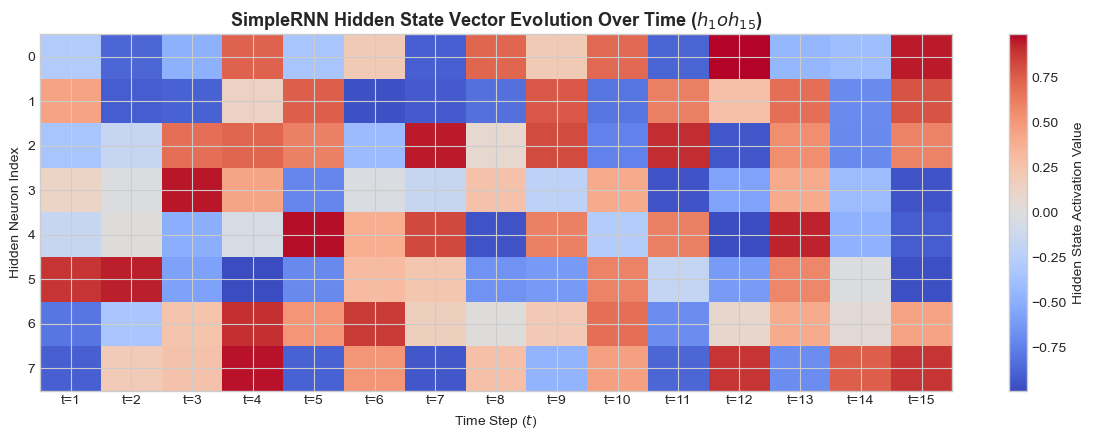

In [3]:
# Visualizing Hidden State Dynamics Across Timesteps
plt.figure(figsize=(12, 4.5))
plt.imshow(hidden_matrix, cmap='coolwarm', aspect='auto', interpolation='nearest')
plt.colorbar(label='Hidden State Activation Value')
plt.title('SimpleRNN Hidden State Vector Evolution Over Time ($h_1 	o h_{15}$)', fontweight='bold')
plt.xlabel('Time Step ($t$)')
plt.ylabel('Hidden Neuron Index')
plt.xticks(range(T_steps), [f't={i+1}' for i in range(T_steps)])
plt.tight_layout()
plt.show()


## 3. The Vanishing Gradient Dilemma in BPTT
In Backpropagation Through Time, the error gradient at timestep $t$ must flow back to timestep $k < t$ via:
$$\frac{\partial h_t}{\partial h_k} = \prod_{j=k+1}^t \frac{\partial h_j}{\partial h_{j-1}} = \prod_{j=k+1}^t W_{hh}^T \text{diag}(1 - h_j^2)$$

Because $\tanh' \le 1$ and spectral norms of $W_{hh}$ are frequently $< 1$, multiplying matrices across 10+ timesteps causes gradients to **decay exponentially to 0**.
* Early words in a sequence receive zero gradient signal.
* The model forgets long-term context (e.g., matching a subject at word 1 to a verb at word 15).
* **The Solution**: Gated architectures with constant error carousels (**LSTM** and **GRU**), explored in Notebook 2!
